In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
import warnings
warnings.filterwarnings('ignore')

In [115]:
#step 1: load and inspect data
df=pd.read_csv("C:\\New_projects\\House_ban\\Data\\bengaluru_house_prices.csv")

EDA

In [116]:
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [117]:
df.columns.tolist()

['area_type',
 'availability',
 'location',
 'size',
 'society',
 'total_sqft',
 'bath',
 'balcony',
 'price']

In [118]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   availability  13320 non-null  str    
 2   location      13319 non-null  str    
 3   size          13304 non-null  str    
 4   society       7818 non-null   str    
 5   total_sqft    13320 non-null  str    
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), str(6)
memory usage: 936.7 KB


In [119]:
df.shape

(13320, 9)

In [120]:
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [121]:
df.describe(include='object').T

,count,unique,top,freq
area_type,13320,4,Super built-up Area,8790
availability,13320,81,Ready To Move,10581
location,13319,1305,Whitefield,540
size,13304,31,2 BHK,5199
society,7818,2688,GrrvaGr,80
total_sqft,13320,2117,1200,843


In [122]:
df.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [123]:
df.isnull().sum()/len(df)*100

area_type        0.000000
availability     0.000000
location         0.007508
size             0.120120
society         41.306306
total_sqft       0.000000
bath             0.548048
balcony          4.572072
price            0.000000
dtype: float64

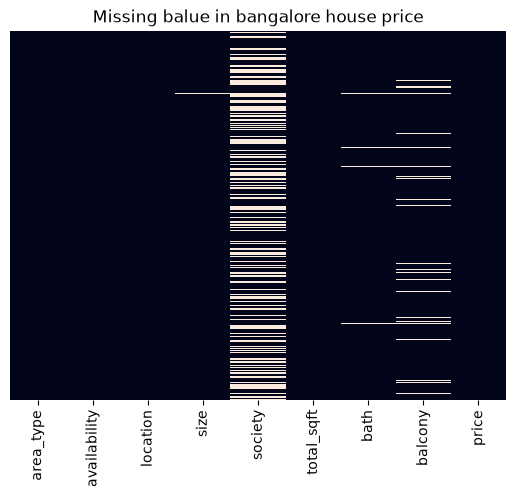

In [124]:
plt.Figure(figsize=(10,8))
sns.heatmap(df.isnull(),cbar=False,yticklabels=False)
plt.title('Missing balue in bangalore house price')
plt.show()

In [125]:
print(df.duplicated().sum())

529


 Step 3 — Perform exploratory data analysis (EDA)

In [127]:
display(df[df.duplicated(keep=False)].head(20))

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
8,Super built-up Area,Ready To Move,Marathahalli,3 BHK,NaN,1310,3.0,1.0,63.25
33,Super built-up Area,Ready To Move,Raja Rajeshwari Nagar,3 BHK,GrrvaGr,1693,3.0,3.0,57.39
35,Super built-up Area,21-Dec,Kanakpura Road,2 BHK,PrarePa,700,2.0,1.0,36.00
38,Super built-up Area,Ready To Move,Chikkalasandra,3 BHK,NaN,1290,2.0,2.0,56.12
55,Super built-up Area,Ready To Move,Begur Road,2 BHK,Dhalsh,1200,2.0,2.0,44.00
83,Super built-up Area,Ready To Move,Garudachar Palya,3 BHK,NaN,1325,2.0,2.0,60.80
112,Super built-up Area,Ready To Move,Whitefield,2 BHK,Sonviik,1116,2.0,1.0,51.91
125,Built-up Area,Ready To Move,Kadugodi,2 BHK,NaN,1050,2.0,1.0,34.00
139,Super built-up Area,19-Jan,Chandra Layout,3 BHK,TiaksAa,1260,2.0,2.0,85.05
143,Super built-up Area,Ready To Move,ISRO Layout,2 BHK,NaN,1000,2.0,1.0,60.00


Separate numeric and categorical columns

In [130]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

In [131]:
categorical_cols=df.select_dtypes(include=['object','category','string']).columns.to_list()

In [135]:
for i in df.columns:
    print(f'{i:20} --> {df[i].nunique()} unique values')

area_type            --> 4 unique values
availability         --> 81 unique values
location             --> 1305 unique values
size                 --> 31 unique values
society              --> 2688 unique values
total_sqft           --> 2117 unique values
bath                 --> 19 unique values
balcony              --> 4 unique values
price                --> 1994 unique values


6. Analyze the target column — price

In [137]:
print(df["price"].describe())

count    13320.000000
mean       112.565627
std        148.971674
min          8.000000
25%         50.000000
50%         72.000000
75%        120.000000
max       3600.000000
Name: price, dtype: float64


In [138]:
print("Minimum price:", df["price"].min())
print("Maximum price:", df["price"].max())
print("Mean price:", df["price"].mean())
print("Median price:", df["price"].median())

Minimum price: 8.0
Maximum price: 3600.0
Mean price: 112.5656265015015
Median price: 72.0


<function matplotlib.pyplot.show(close=None, block=None)>

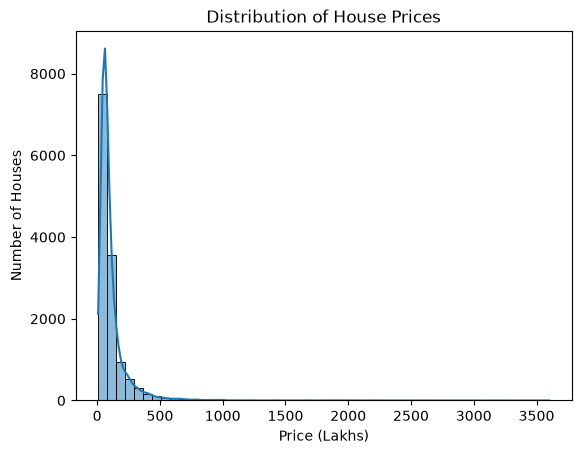

In [141]:
plt.Figure(figsize=(10,8))
sns.histplot(data=df,x='price',bins=50,kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Price (Lakhs)")
plt.ylabel("Number of Houses")
plt.show

Box plot to inspect potential outliers

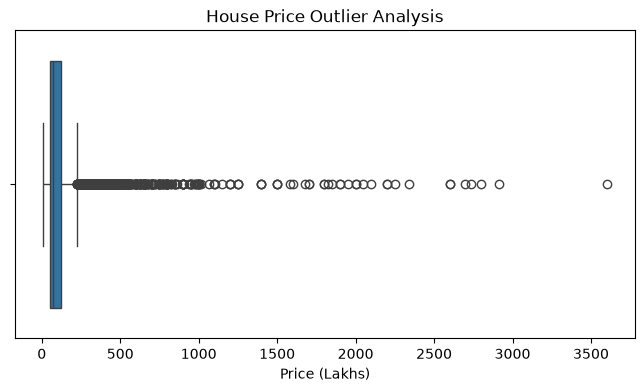

In [142]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["price"])

plt.title("House Price Outlier Analysis")
plt.xlabel("Price (Lakhs)")
plt.show()

Correlation between numeric columns

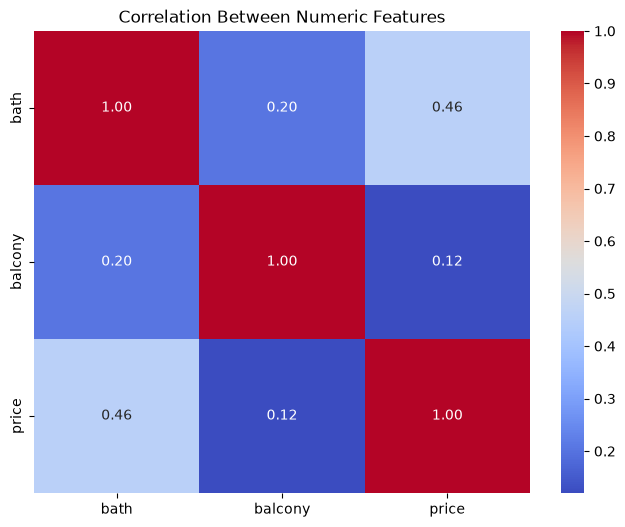

In [143]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(8, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numeric Features")
plt.show()

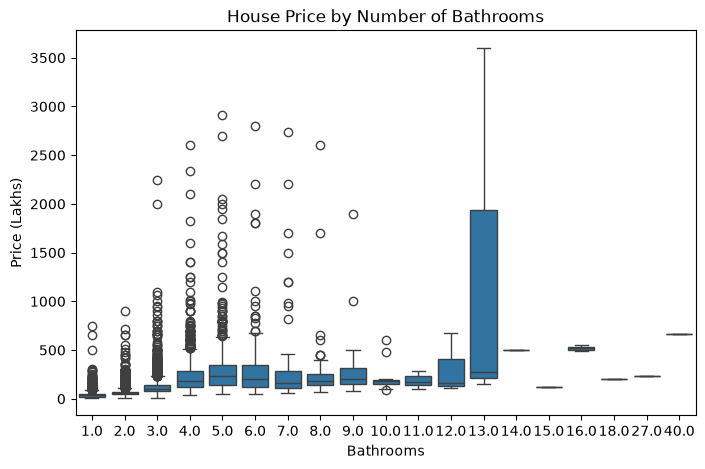

In [144]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="bath",
    y="price"
)

plt.title("House Price by Number of Bathrooms")
plt.xlabel("Bathrooms")
plt.ylabel("Price (Lakhs)")
plt.show()

8. Analyze categorical features

A. Number of properties by area type

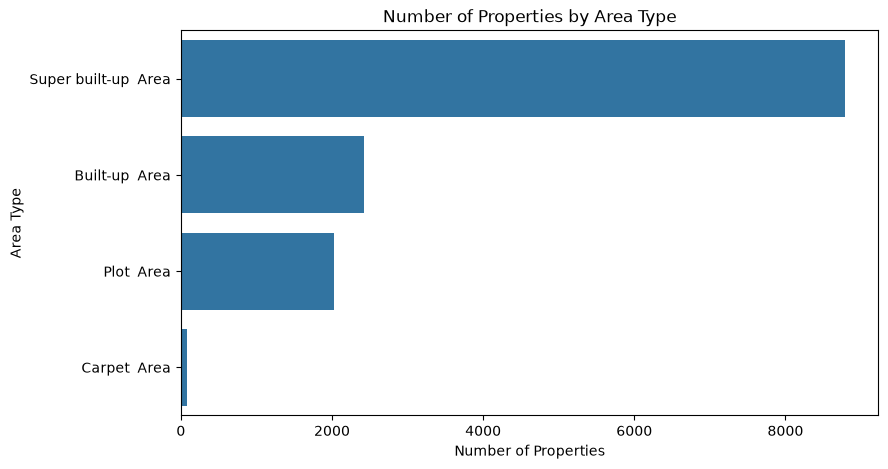

In [145]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    y="area_type",
    order=df["area_type"].value_counts().index
)

plt.title("Number of Properties by Area Type")
plt.xlabel("Number of Properties")
plt.ylabel("Area Type")
plt.show()

B. Most common locations

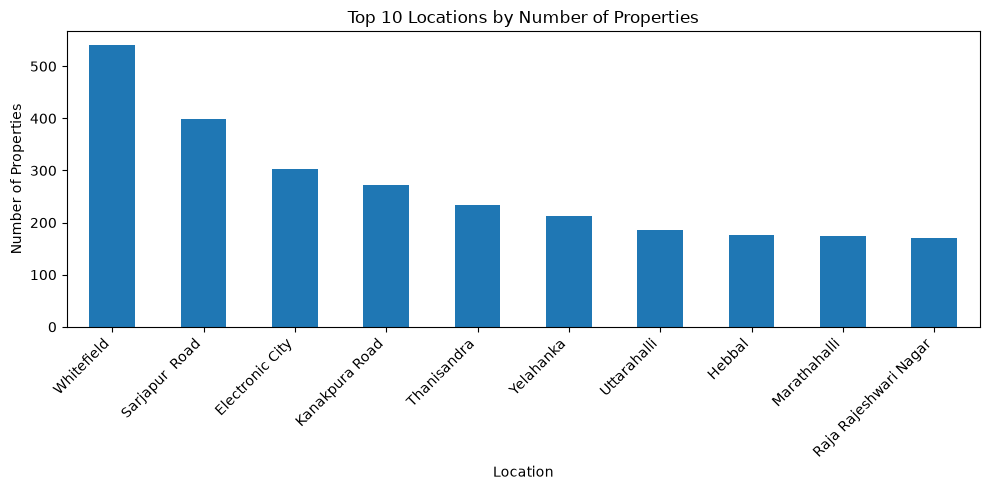

In [146]:
top_locations = df["location"].value_counts().head(10)

top_locations.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Locations by Number of Properties")
plt.xlabel("Location")
plt.ylabel("Number of Properties")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

C. Price by area type

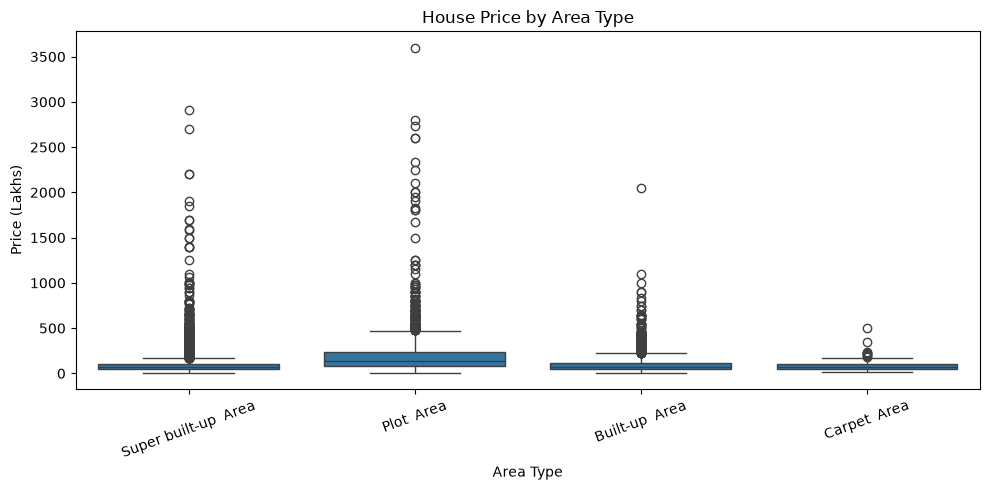

In [147]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="area_type",
    y="price"
)

plt.title("House Price by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Price (Lakhs)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

9. Investigate total_sqft

In [148]:
print(df["total_sqft"].dtype)

display(df["total_sqft"].value_counts().head(20))

str


total_sqft
1200    843
1100    221
1500    205
2400    196
600     180
1000    172
1350    133
1050    123
1300    117
1250    114
900     112
1400    108
1800    104
1600    101
1150    101
1140     91
2000     83
1450     70
1650     69
800      67
Name: count, dtype: int64

In [149]:
sqft_numeric = pd.to_numeric(
    df["total_sqft"],
    errors="coerce"
)

print(
    "Values not directly numeric:",
    sqft_numeric.isna().sum()
)

Values not directly numeric: 247


In [150]:
print("========== EDA SUMMARY ==========")

print("\nDataset shape:")
print(df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nNumeric summary:")
display(df.describe().T)

print("\nPrice summary:")
display(df["price"].describe())

print("\nTop 10 locations:")
display(df["location"].value_counts().head(10))

========== EDA SUMMARY ==========

Dataset shape:
(13320, 9)

Data types:
area_type           str
availability        str
location            str
size                str
society             str
total_sqft          str
bath            float64
balcony         float64
price           float64
dtype: object

Missing values:
area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

Duplicate rows:
529

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
bath,13247.0,2.692610,1.341458,1.0,2.0,2.0,3.0,40.0
balcony,12711.0,1.584376,0.817263,0.0,1.0,2.0,2.0,3.0
price,13320.0,112.565627,148.971674,8.0,50.0,72.0,120.0,3600.0



Price summary:


count    13320.000000
mean       112.565627
std        148.971674
min          8.000000
25%         50.000000
50%         72.000000
75%        120.000000
max       3600.000000
Name: price, dtype: float64


Top 10 locations:


location
Whitefield               540
Sarjapur  Road           399
Electronic City          302
Kanakpura Road           273
Thanisandra              234
Yelahanka                213
Uttarahalli              186
Hebbal                   177
Marathahalli             175
Raja Rajeshwari Nagar    171
Name: count, dtype: int64